# FD004 Paper 1 — Master Comparison, Persistent-Failure Analysis, and Freeze

## Purpose
This notebook is the **final Paper 1 consolidation step** after the standard/IID analysis, DS-A held-out-regime shift, and DS-B restricted-operating-envelope shift.

It will:

1. consolidate the final standard/IID, DS-A, and DS-B results;
2. compare Asymmetric CQR and Balanced Engine CQR across all conditions;
3. identify persistent problem engines across DS-A and DS-B;
4. compare life-stage failure patterns;
5. quantify robustness degradation relative to the standard/IID condition;
6. generate the final Paper 1 master tables and figures;
7. create a reproducibility/freeze manifest;
8. export a compact final results package for manuscript writing.

## Paper 1 decision rule
No further model tuning should be performed from this notebook.  
Any remaining work after this notebook should be:
- clean reproducibility rerun,
- manuscript/table/figure refinement,
- archival/freeze,
- transition to Paper 2.

## Verified DS-A headline results
- RMSE: 24.869
- MAE: 14.869
- Asymmetric CQR coverage: 73.13%
- Asymmetric mean width: 45.00
- Balanced Engine CQR coverage: 90.21%
- Balanced mean width: 66.74
- Balanced engines ≥80%: 26 / 38
- Balanced worst-engine coverage: 52.00%
- RMSE vs Balanced coverage correlation: -0.953
- Mid-life Balanced coverage: 70.88%
- Problem-engine mid-life coverage: 33.87%

## Verified DS-B headline results
- RMSE: 23.999
- MAE: 15.329
- Asymmetric CQR coverage: 75.97%
- Asymmetric mean width: 45.325
- Balanced Engine CQR coverage: 90.63%
- Balanced mean width: 70.252
- Balanced engines ≥80%: 27 / 38
- Balanced worst-engine coverage: 50.00%
- RMSE vs Balanced coverage correlation: -0.916
- Mid-life Balanced coverage: 75.16%
- Problem-engine mid-life coverage: 34.58%

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Imports and output directory

In [31]:
import os
import json
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

OUTPUT_DIR = Path("/content/drive/MyDrive/FD004_Paper1_Freeze")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Paper 1 freeze output:", OUTPUT_DIR)

Paper 1 freeze output: /content/drive/MyDrive/FD004_Paper1_Freeze


## 2. Standard/IID final result files

Point these paths to the final Paper 1 package if running in Colab.

The default filenames correspond to the final results package already used in the consolidated report.

In [32]:
STANDARD_RESULTS_DIR = Path(
    "/content/drive/MyDrive/FD004_Final_Results_Package"
)

GLOBAL_METHODS_CSV = STANDARD_RESULTS_DIR / "Table_1_Global_Uncertainty_Methods.csv"
ENGINE_RELIABILITY_CSV = STANDARD_RESULTS_DIR / "Table_2_Engine_Reliability.csv"
STANDARD_PROBLEM_ENGINES_CSV = STANDARD_RESULTS_DIR / "Table_3_Persistent_Problem_Engines.csv"
DIAGNOSTIC_ABLATIONS_CSV = STANDARD_RESULTS_DIR / "Table_4_Diagnostic_Ablations.csv"

print("Expected standard/IID files:")
for p in [
    GLOBAL_METHODS_CSV,
    ENGINE_RELIABILITY_CSV,
    STANDARD_PROBLEM_ENGINES_CSV,
    DIAGNOSTIC_ABLATIONS_CSV,
]:
    print(" -", p)

Expected standard/IID files:
 - /content/drive/MyDrive/FD004_Final_Results_Package/Table_1_Global_Uncertainty_Methods.csv
 - /content/drive/MyDrive/FD004_Final_Results_Package/Table_2_Engine_Reliability.csv
 - /content/drive/MyDrive/FD004_Final_Results_Package/Table_3_Persistent_Problem_Engines.csv
 - /content/drive/MyDrive/FD004_Final_Results_Package/Table_4_Diagnostic_Ablations.csv


## 3. Optional DS-A and DS-B result directories

If you exported the CSV files from the notebooks, set these directories correctly.

If some files are absent, the notebook uses the verified headline values embedded below for the master comparison. Engine-level comparisons still use the verified problem-engine lists.

In [33]:
DS_A_RESULTS_DIR = Path(
    "/content/drive/MyDrive/FD004_DS_A_Results"
)

DS_B_RESULTS_DIR = Path(
    "/content/drive/MyDrive/FD004_DS_B_Results"
)

print("DS-A results:", DS_A_RESULTS_DIR)
print("DS-B results:", DS_B_RESULTS_DIR)

DS-A results: /content/drive/MyDrive/FD004_DS_A_Results
DS-B results: /content/drive/MyDrive/FD004_DS_B_Results


## 4. Verified reference values from completed DS-A and DS-B runs

In [34]:
DS_A_REFERENCE = {
    "experiment": "DS-A: Held-out Regime 0",
    "rmse": 24.869,
    "mae": 14.869,
    "asym_coverage": 73.13,
    "asym_width": 45.00,
    "balanced_coverage": 90.21,
    "balanced_width": 66.74,
    "balanced_engines_at_target": 26,
    "n_test_engines": 38,
    "balanced_worst_engine_coverage": 52.00,
    "rmse_coverage_corr": -0.953,
    "midlife_balanced_coverage": 70.88,
    "problem_midlife_balanced_coverage": 33.87,
}

DS_B_REFERENCE = {
    "experiment": "DS-B: Restricted operating envelope",
    "rmse": 23.999,
    "mae": 15.329,
    "asym_coverage": 75.97,
    "asym_width": 45.325,
    "balanced_coverage": 90.63,
    "balanced_width": 70.252,
    "balanced_engines_at_target": 27,
    "n_test_engines": 38,
    "balanced_worst_engine_coverage": 50.00,
    "rmse_coverage_corr": -0.916,
    "midlife_balanced_coverage": 75.16,
    "problem_midlife_balanced_coverage": 34.58,
    "envelope_excess_abs_error_corr": 0.029,
    "envelope_excess_balanced_coverage_corr": -0.043,
}

DS_A_PROBLEM_ENGINES = [
    17, 156, 240, 115, 120, 194,
    245, 181, 105, 25, 184, 201
]

DS_B_PROBLEM_ENGINES = [
    156, 240, 17, 184, 39, 105,
    245, 120, 181, 194, 200
]

print("DS-A problem engines:", len(DS_A_PROBLEM_ENGINES))
print("DS-B problem engines:", len(DS_B_PROBLEM_ENGINES))

DS-A problem engines: 12
DS-B problem engines: 11


## 5. Load final standard/IID tables

If the package is not at the default path, upload/copy the four CSV files and update `STANDARD_RESULTS_DIR`.

In [35]:
def safe_read_csv(path):
    path = Path(path)
    if path.exists():
        print("Loaded:", path.name)
        return pd.read_csv(path)
    print("Not found:", path)
    return None


global_methods = safe_read_csv(GLOBAL_METHODS_CSV)
engine_reliability = safe_read_csv(ENGINE_RELIABILITY_CSV)
standard_problem_engines = safe_read_csv(STANDARD_PROBLEM_ENGINES_CSV)
diagnostic_ablations = safe_read_csv(DIAGNOSTIC_ABLATIONS_CSV)

if global_methods is not None:
    display(global_methods)

if engine_reliability is not None:
    display(engine_reliability)

Loaded: Table_1_Global_Uncertainty_Methods.csv
Loaded: Table_2_Engine_Reliability.csv
Loaded: Table_3_Persistent_Problem_Engines.csv
Loaded: Table_4_Diagnostic_Ablations.csv


,Method,PICP (%),MPIW,Winkler,Lower violation (%),Upper violation (%),Crossing (%)
0,Raw Quantiles,72.99,42.71,77.17,9.29,17.72,0.0
1,Window CQR,83.04,51.84,76.47,6.23,10.73,0.0
2,Asymmetric CQR,83.24,51.50,76.03,6.75,10.01,0.0
3,Balanced Engine CQR,91.67,72.30,84.13,2.71,5.62,0.0


,Method,Mean engine PICP (%),Median engine PICP (%),10th pct PICP (%),25th pct PICP (%),Worst engine PICP (%),Engines <80%,Engines <70%,Mean MPIW,Mean Winkler
0,Raw Quantiles,71.48,72.72,49.74,56.26,39.22,16,11,42.71,77.27
1,Window CQR,81.93,83.54,63.34,70.51,55.21,11,6,51.83,75.97
2,Asymmetric CQR,81.87,82.48,63.42,69.99,48.04,10,6,51.50,76.12
3,Balanced Engine CQR,91.44,95.90,74.90,88.10,68.57,5,1,72.26,82.96


## 6. Extract standard/IID uncertainty values

This cell is tolerant to minor column-name differences. It extracts the final Asymmetric CQR and Balanced Engine CQR values from the final results package.

In [36]:
def extract_method_row(df, method_name):
    if df is None:
        return None

    method_col = None
    for c in df.columns:
        if str(c).strip().lower() == "method":
            method_col = c
            break

    if method_col is None:
        raise ValueError("No Method column found.")

    mask = (
        df[method_col]
        .astype(str)
        .str.strip()
        .str.lower()
        == method_name.lower()
    )

    if not mask.any():
        raise ValueError(
            f"Method '{method_name}' not found."
        )

    return df.loc[mask].iloc[0]


iid_asym_global = extract_method_row(
    global_methods,
    "Asymmetric CQR"
) if global_methods is not None else None

iid_bal_global = extract_method_row(
    global_methods,
    "Balanced Engine CQR"
) if global_methods is not None else None

iid_asym_engine = extract_method_row(
    engine_reliability,
    "Asymmetric CQR"
) if engine_reliability is not None else None

iid_bal_engine = extract_method_row(
    engine_reliability,
    "Balanced Engine CQR"
) if engine_reliability is not None else None

print("IID rows extracted.")
if iid_asym_global is not None:
    display(pd.DataFrame([iid_asym_global, iid_bal_global]))

IID rows extracted.


,Method,PICP (%),MPIW,Winkler,Lower violation (%),Upper violation (%),Crossing (%)
2,Asymmetric CQR,83.24,51.5,76.03,6.75,10.01,0.0
3,Balanced Engine CQR,91.67,72.3,84.13,2.71,5.62,0.0


## 7. Helper for flexible column extraction

In [37]:
def first_numeric_value(row, candidates):
    if row is None:
        return np.nan

    normalized = {
        str(c).strip().lower(): c
        for c in row.index
    }

    for candidate in candidates:
        key = candidate.strip().lower()
        if key in normalized:
            value = row[normalized[key]]
            try:
                return float(value)
            except Exception:
                pass

    return np.nan


iid_asym_coverage = first_numeric_value(
    iid_asym_global,
    ["PICP (%)", "Coverage (%)", "Coverage"]
)

iid_bal_coverage = first_numeric_value(
    iid_bal_global,
    ["PICP (%)", "Coverage (%)", "Coverage"]
)

iid_asym_width = first_numeric_value(
    iid_asym_global,
    ["MPIW", "Mean MPIW", "Mean Width", "Width"]
)

iid_bal_width = first_numeric_value(
    iid_bal_global,
    ["MPIW", "Mean MPIW", "Mean Width", "Width"]
)

iid_asym_engine_mean = first_numeric_value(
    iid_asym_engine,
    ["Mean engine PICP (%)", "Mean PICP (%)"]
)

iid_bal_engine_mean = first_numeric_value(
    iid_bal_engine,
    ["Mean engine PICP (%)", "Mean PICP (%)"]
)

iid_asym_worst = first_numeric_value(
    iid_asym_engine,
    ["Worst engine PICP (%)", "Worst PICP (%)", "Min engine PICP (%)"]
)

iid_bal_worst = first_numeric_value(
    iid_bal_engine,
    ["Worst engine PICP (%)", "Worst PICP (%)", "Min engine PICP (%)"]
)

print("IID Asymmetric coverage:", iid_asym_coverage)
print("IID Balanced coverage:", iid_bal_coverage)
print("IID Asymmetric width:", iid_asym_width)
print("IID Balanced width:", iid_bal_width)

IID Asymmetric coverage: 83.24
IID Balanced coverage: 91.67
IID Asymmetric width: 51.5
IID Balanced width: 72.3


## 8. Build the Paper 1 master uncertainty table

The final package reports standard/IID coverage of approximately:
- Asymmetric CQR: 83.24%
- Balanced Engine CQR: 91.67%

If automatic extraction fails because the CSV schema has changed, the fallback values below preserve the verified final results.

In [38]:
if not np.isfinite(iid_asym_coverage):
    iid_asym_coverage = 83.24

if not np.isfinite(iid_bal_coverage):
    iid_bal_coverage = 91.67

# Verified final package values if width extraction fails.
if not np.isfinite(iid_asym_width):
    iid_asym_width = 51.50

if not np.isfinite(iid_bal_width):
    iid_bal_width = 72.26


master_uncertainty = pd.DataFrame([
    {
        "Condition": "Standard / IID",
        "Method": "Asymmetric CQR",
        "Coverage (%)": iid_asym_coverage,
        "Mean Width": iid_asym_width
    },
    {
        "Condition": "Standard / IID",
        "Method": "Balanced Engine CQR",
        "Coverage (%)": iid_bal_coverage,
        "Mean Width": iid_bal_width
    },
    {
        "Condition": "DS-A: Held-out Regime 0",
        "Method": "Asymmetric CQR",
        "Coverage (%)": DS_A_REFERENCE["asym_coverage"],
        "Mean Width": DS_A_REFERENCE["asym_width"]
    },
    {
        "Condition": "DS-A: Held-out Regime 0",
        "Method": "Balanced Engine CQR",
        "Coverage (%)": DS_A_REFERENCE["balanced_coverage"],
        "Mean Width": DS_A_REFERENCE["balanced_width"]
    },
    {
        "Condition": "DS-B: Restricted Envelope",
        "Method": "Asymmetric CQR",
        "Coverage (%)": DS_B_REFERENCE["asym_coverage"],
        "Mean Width": DS_B_REFERENCE["asym_width"]
    },
    {
        "Condition": "DS-B: Restricted Envelope",
        "Method": "Balanced Engine CQR",
        "Coverage (%)": DS_B_REFERENCE["balanced_coverage"],
        "Mean Width": DS_B_REFERENCE["balanced_width"]
    },
])

display(master_uncertainty.round(3))

,Condition,Method,Coverage (%),Mean Width
0,Standard / IID,Asymmetric CQR,83.24,51.500
1,Standard / IID,Balanced Engine CQR,91.67,72.300
2,DS-A: Held-out Regime 0,Asymmetric CQR,73.13,45.000
3,DS-A: Held-out Regime 0,Balanced Engine CQR,90.21,66.740
4,DS-B: Restricted Envelope,Asymmetric CQR,75.97,45.325
5,DS-B: Restricted Envelope,Balanced Engine CQR,90.63,70.252


## 9. Shift-level point-prediction comparison

In [39]:
shift_point_results = pd.DataFrame([
    {
        "Condition": "DS-A: Held-out Regime 0",
        "RMSE": DS_A_REFERENCE["rmse"],
        "MAE": DS_A_REFERENCE["mae"],
        "RMSE–Balanced coverage correlation":
            DS_A_REFERENCE["rmse_coverage_corr"],
    },
    {
        "Condition": "DS-B: Restricted Envelope",
        "RMSE": DS_B_REFERENCE["rmse"],
        "MAE": DS_B_REFERENCE["mae"],
        "RMSE–Balanced coverage correlation":
            DS_B_REFERENCE["rmse_coverage_corr"],
    },
])

display(shift_point_results.round(3))

,Condition,RMSE,MAE,RMSE–Balanced coverage correlation
0,DS-A: Held-out Regime 0,24.869,14.869,-0.953
1,DS-B: Restricted Envelope,23.999,15.329,-0.916


## 10. Quantify coverage degradation relative to IID

Negative values mean coverage worsened under distribution shift.

In [40]:
coverage_change_rows = []

for method in [
    "Asymmetric CQR",
    "Balanced Engine CQR"
]:
    iid_cov = master_uncertainty.loc[
        (master_uncertainty["Condition"] == "Standard / IID")
        & (master_uncertainty["Method"] == method),
        "Coverage (%)"
    ].iloc[0]

    for condition in [
        "DS-A: Held-out Regime 0",
        "DS-B: Restricted Envelope"
    ]:
        shift_cov = master_uncertainty.loc[
            (master_uncertainty["Condition"] == condition)
            & (master_uncertainty["Method"] == method),
            "Coverage (%)"
        ].iloc[0]

        coverage_change_rows.append({
            "Method": method,
            "Shift": condition,
            "IID Coverage (%)": iid_cov,
            "Shift Coverage (%)": shift_cov,
            "Coverage Change (pp)": shift_cov - iid_cov
        })

coverage_change = pd.DataFrame(coverage_change_rows)
display(coverage_change.round(3))

,Method,Shift,IID Coverage (%),Shift Coverage (%),Coverage Change (pp)
0,Asymmetric CQR,DS-A: Held-out Regime 0,83.24,73.13,-10.11
1,Asymmetric CQR,DS-B: Restricted Envelope,83.24,75.97,-7.27
2,Balanced Engine CQR,DS-A: Held-out Regime 0,91.67,90.21,-1.46
3,Balanced Engine CQR,DS-B: Restricted Envelope,91.67,90.63,-1.04


## 11. Coverage-target margin

Positive values are above the 80% nominal target; negative values are below target.

In [41]:
TARGET_COVERAGE = 80.0

target_margin = master_uncertainty.copy()
target_margin["Target Margin (pp)"] = (
    target_margin["Coverage (%)"]
    - TARGET_COVERAGE
)

display(target_margin.round(3))

,Condition,Method,Coverage (%),Mean Width,Target Margin (pp)
0,Standard / IID,Asymmetric CQR,83.24,51.500,3.24
1,Standard / IID,Balanced Engine CQR,91.67,72.300,11.67
2,DS-A: Held-out Regime 0,Asymmetric CQR,73.13,45.000,-6.87
3,DS-A: Held-out Regime 0,Balanced Engine CQR,90.21,66.740,10.21
4,DS-B: Restricted Envelope,Asymmetric CQR,75.97,45.325,-4.03
5,DS-B: Restricted Envelope,Balanced Engine CQR,90.63,70.252,10.63


## 12. Figure — coverage across IID, DS-A and DS-B

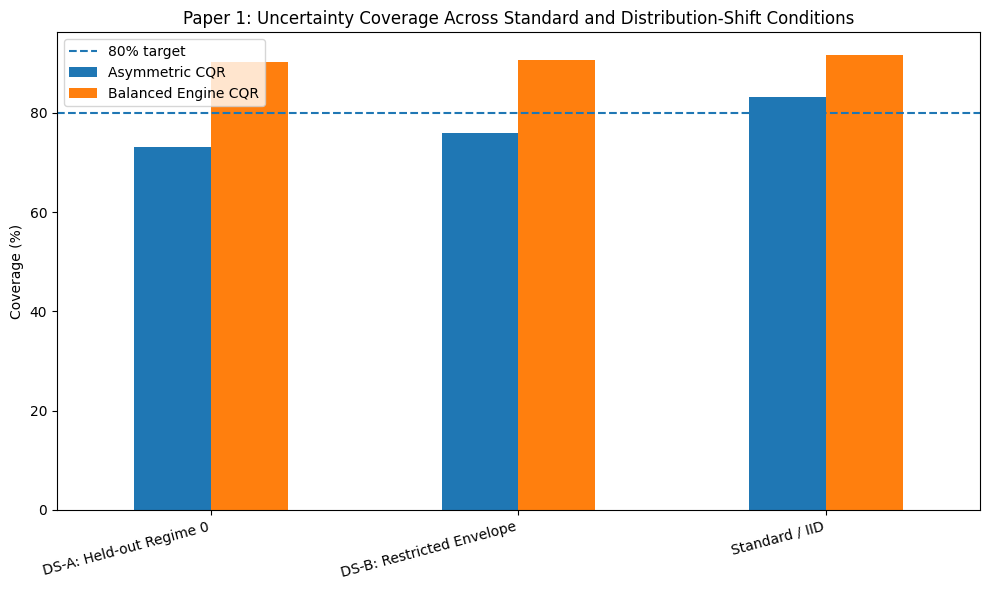

Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Figure_Paper1_Coverage_Across_Conditions.png


In [42]:
coverage_pivot = master_uncertainty.pivot(
    index="Condition",
    columns="Method",
    values="Coverage (%)"
)

ax = coverage_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.axhline(
    80,
    linestyle="--",
    label="80% target"
)

ax.set_ylabel("Coverage (%)")
ax.set_xlabel("")
ax.set_title(
    "Paper 1: Uncertainty Coverage Across Standard and Distribution-Shift Conditions"
)

plt.xticks(rotation=15, ha="right")
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "Figure_Paper1_Coverage_Across_Conditions.png"
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

## 13. Figure — coverage versus interval width

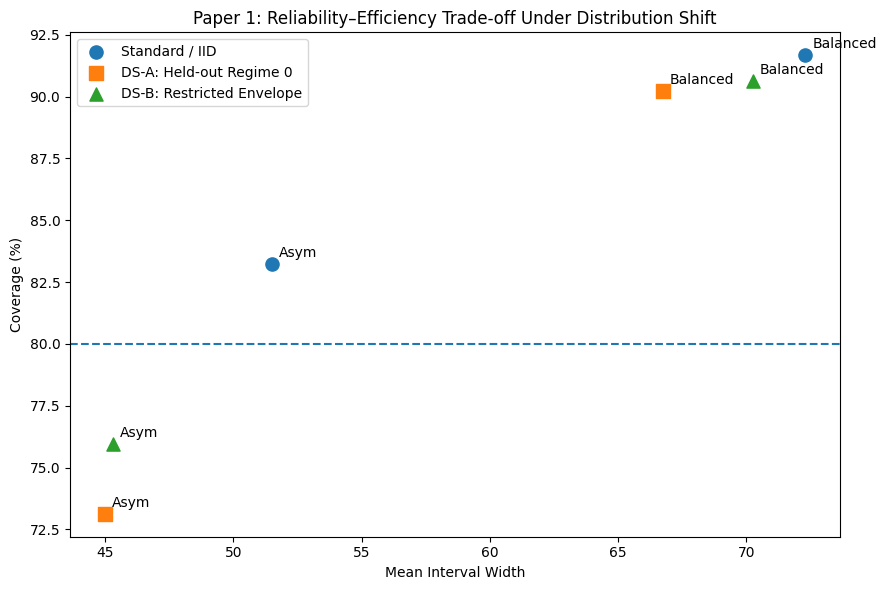

Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Figure_Paper1_Coverage_vs_Width.png


In [43]:
plt.figure(figsize=(9, 6))

markers = {
    "Standard / IID": "o",
    "DS-A: Held-out Regime 0": "s",
    "DS-B: Restricted Envelope": "^",
}

for condition in master_uncertainty["Condition"].unique():
    sub = master_uncertainty[
        master_uncertainty["Condition"] == condition
    ]

    plt.scatter(
        sub["Mean Width"],
        sub["Coverage (%)"],
        marker=markers.get(condition, "o"),
        s=90,
        label=condition
    )

    for _, row in sub.iterrows():
        label = (
            "Asym"
            if row["Method"] == "Asymmetric CQR"
            else "Balanced"
        )

        plt.annotate(
            label,
            (
                row["Mean Width"],
                row["Coverage (%)"]
            ),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.axhline(
    80,
    linestyle="--"
)

plt.xlabel("Mean Interval Width")
plt.ylabel("Coverage (%)")
plt.title(
    "Paper 1: Reliability–Efficiency Trade-off Under Distribution Shift"
)

plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "Figure_Paper1_Coverage_vs_Width.png"
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

# Persistent problem-engine analysis

## 14. Compare DS-A and DS-B problem-engine sets

In [44]:
dsa = set(DS_A_PROBLEM_ENGINES)
dsb = set(DS_B_PROBLEM_ENGINES)

persistent_shift_engines = sorted(
    dsa & dsb
)

dsa_only_engines = sorted(
    dsa - dsb
)

dsb_only_engines = sorted(
    dsb - dsa
)

problem_overlap = pd.DataFrame({
    "Category": [
        "DS-A problem engines",
        "DS-B problem engines",
        "Persistent across DS-A and DS-B",
        "DS-A only",
        "DS-B only"
    ],
    "Count": [
        len(dsa),
        len(dsb),
        len(persistent_shift_engines),
        len(dsa_only_engines),
        len(dsb_only_engines)
    ],
    "Engines": [
        ", ".join(map(str, sorted(dsa))),
        ", ".join(map(str, sorted(dsb))),
        ", ".join(map(str, persistent_shift_engines)),
        ", ".join(map(str, dsa_only_engines)),
        ", ".join(map(str, dsb_only_engines))
    ]
})

display(problem_overlap)

print(
    "Persistent shift-problem engines:",
    persistent_shift_engines
)

,Category,Count,Engines
0,DS-A problem engines,12,"17, 25, 105, 115, 120, 156, 181, 184, 194, 201..."
1,DS-B problem engines,11,"17, 39, 105, 120, 156, 181, 184, 194, 200, 240..."
2,Persistent across DS-A and DS-B,9,"17, 105, 120, 156, 181, 184, 194, 240, 245"
3,DS-A only,3,"25, 115, 201"
4,DS-B only,2,"39, 200"


Persistent shift-problem engines: [17, 105, 120, 156, 181, 184, 194, 240, 245]


## 15. Jaccard overlap between DS-A and DS-B problem-engine sets

In [45]:
intersection = len(dsa & dsb)
union = len(dsa | dsb)

jaccard = intersection / union

print("Intersection:", intersection)
print("Union:", union)
print(f"Jaccard overlap: {jaccard:.3f}")
print(
    f"{100*intersection/len(dsa):.1f}% of DS-A problem engines "
    "also fail in DS-B."
)
print(
    f"{100*intersection/len(dsb):.1f}% of DS-B problem engines "
    "also fail in DS-A."
)

Intersection: 9
Union: 14
Jaccard overlap: 0.643
75.0% of DS-A problem engines also fail in DS-B.
81.8% of DS-B problem engines also fail in DS-A.


## 16. Compare with standard/IID persistent problem engines

The final standard results package identified a smaller persistent hard-engine set.  
This cell checks whether those same standard hard engines also appear among the shift failures.

In [46]:
if standard_problem_engines is not None:

    engine_col = None
    for c in standard_problem_engines.columns:
        if str(c).strip().lower() in [
            "engine",
            "engine_id",
            "unit_id"
        ]:
            engine_col = c
            break

    if engine_col is None:
        raise ValueError(
            "Could not identify engine column "
            "in standard problem-engine table."
        )

    standard_hard = set(
        standard_problem_engines[engine_col]
        .astype(int)
        .tolist()
    )

    display(standard_problem_engines)

    print(
        "Standard hard engines:",
        sorted(standard_hard)
    )

    print(
        "Overlap standard vs DS-A:",
        sorted(standard_hard & dsa)
    )

    print(
        "Overlap standard vs DS-B:",
        sorted(standard_hard & dsb)
    )

    print(
        "Persistent across standard, DS-A and DS-B:",
        sorted(
            standard_hard
            & dsa
            & dsb
        )
    )

else:
    standard_hard = set()
    print(
        "Standard problem-engine CSV not available; "
        "shift-overlap analysis remains valid."
    )

,Engine,Windows,RMSE,MAE,Mean bias (pred-true),Balanced PICP (%),Below-lower miss (%),Above-upper miss (%),Mean 5NN distance,OOD rank
0,1,192,24.61,20.06,-19.26,72.92,0.00,27.08,5.501,1
1,24,102,40.84,35.95,35.95,74.51,25.49,0.00,1.818,8
2,36,350,34.90,22.58,-22.37,68.57,0.00,31.43,2.114,4
3,37,230,31.39,19.31,-10.79,79.13,0.87,20.00,1.919,6
4,49,182,38.63,27.16,27.14,75.82,24.18,0.00,1.055,17


Standard hard engines: [1, 24, 36, 37, 49]
Overlap standard vs DS-A: []
Overlap standard vs DS-B: []
Persistent across standard, DS-A and DS-B: []


## 17. Create engine × condition failure matrix

`1` means the engine falls below the 80% Balanced Engine CQR target in that condition.

In [47]:
all_shift_problem_engines = sorted(
    dsa | dsb
)

failure_matrix = pd.DataFrame({
    "engine_id": all_shift_problem_engines
})

failure_matrix["DS_A_problem"] = (
    failure_matrix["engine_id"]
    .isin(dsa)
    .astype(int)
)

failure_matrix["DS_B_problem"] = (
    failure_matrix["engine_id"]
    .isin(dsb)
    .astype(int)
)

if standard_hard:
    failure_matrix["Standard_hard"] = (
        failure_matrix["engine_id"]
        .isin(standard_hard)
        .astype(int)
    )

failure_matrix["Shift_failure_count"] = (
    failure_matrix[
        ["DS_A_problem", "DS_B_problem"]
    ].sum(axis=1)
)

failure_matrix = failure_matrix.sort_values(
    [
        "Shift_failure_count",
        "engine_id"
    ],
    ascending=[False, True]
)

display(failure_matrix)

,engine_id,DS_A_problem,DS_B_problem,Standard_hard,Shift_failure_count
0,17,1,1,0,2
3,105,1,1,0,2
5,120,1,1,0,2
6,156,1,1,0,2
7,181,1,1,0,2
8,184,1,1,0,2
9,194,1,1,0,2
12,240,1,1,0,2
13,245,1,1,0,2
1,25,1,0,0,1


## 18. Figure — persistent shift-problem engines

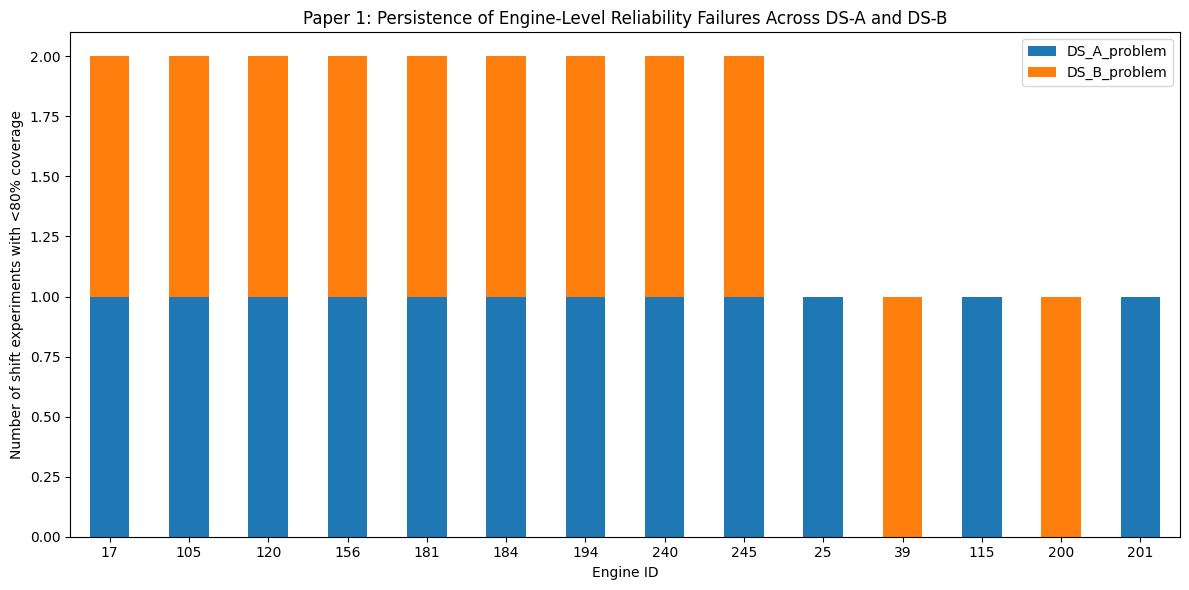

Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Figure_Paper1_Persistent_Shift_Engines.png


In [48]:
plot_failure = failure_matrix.set_index(
    "engine_id"
)[
    ["DS_A_problem", "DS_B_problem"]
]

ax = plot_failure.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

ax.set_ylabel("Number of shift experiments with <80% coverage")
ax.set_xlabel("Engine ID")
ax.set_title(
    "Paper 1: Persistence of Engine-Level Reliability Failures Across DS-A and DS-B"
)

plt.xticks(rotation=0)
plt.tight_layout()

path = OUTPUT_DIR / "Figure_Paper1_Persistent_Shift_Engines.png"
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

# Life-stage comparison

## 19. Verified DS-A / DS-B life-stage results

Replace the optional early/late values below with exported CSV values if desired.  
The mid-life values are the critical verified headline findings.

In [49]:
# Verified from completed notebooks / reports.
life_stage_comparison = pd.DataFrame([
    {
        "Condition": "DS-A",
        "Life Stage": "Early",
        "RMSE": 16.40,
        "Balanced Coverage (%)": 96.09
    },
    {
        "Condition": "DS-A",
        "Life Stage": "Mid",
        "RMSE": 41.98,
        "Balanced Coverage (%)": 70.88
    },
    {
        "Condition": "DS-A",
        "Life Stage": "Late",
        "RMSE": 24.60,
        "Balanced Coverage (%)": 90.52
    },
    {
        "Condition": "DS-B",
        "Life Stage": "Early",
        "RMSE": 17.165,
        "Balanced Coverage (%)": 94.72
    },
    {
        "Condition": "DS-B",
        "Life Stage": "Mid",
        "RMSE": 40.592,
        "Balanced Coverage (%)": 75.16
    },
    {
        "Condition": "DS-B",
        "Life Stage": "Late",
        "RMSE": 19.539,
        "Balanced Coverage (%)": 93.38
    },
])

display(life_stage_comparison.round(3))

,Condition,Life Stage,RMSE,Balanced Coverage (%)
0,DS-A,Early,16.400,96.09
1,DS-A,Mid,41.980,70.88
2,DS-A,Late,24.600,90.52
3,DS-B,Early,17.165,94.72
4,DS-B,Mid,40.592,75.16
5,DS-B,Late,19.539,93.38


## 20. Figure — Balanced Engine CQR coverage by life stage

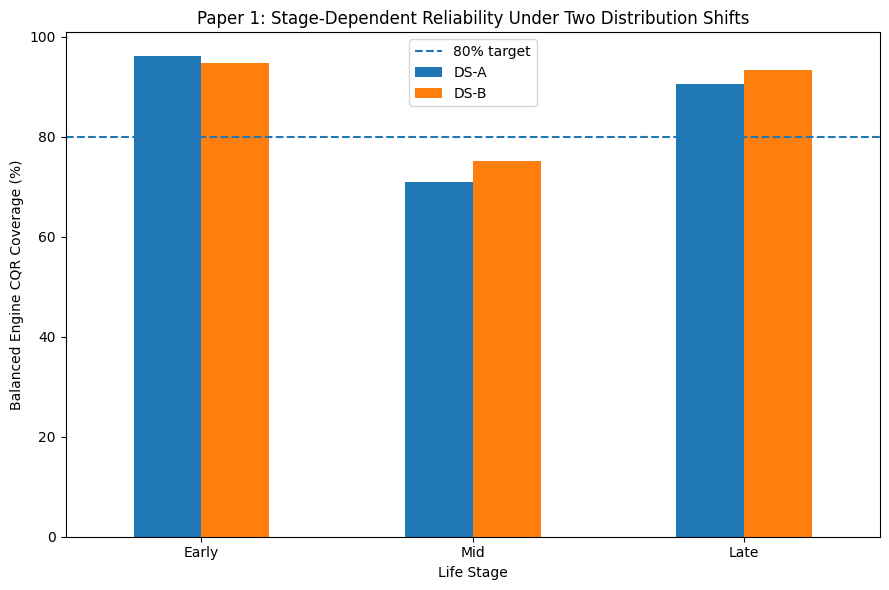

Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Figure_Paper1_Life_Stage_Shift_Comparison.png


In [50]:
stage_pivot = life_stage_comparison.pivot(
    index="Life Stage",
    columns="Condition",
    values="Balanced Coverage (%)"
).reindex(["Early", "Mid", "Late"])

ax = stage_pivot.plot(
    kind="bar",
    figsize=(9, 6)
)

ax.axhline(
    80,
    linestyle="--",
    label="80% target"
)

ax.set_ylabel("Balanced Engine CQR Coverage (%)")
ax.set_xlabel("Life Stage")
ax.set_title(
    "Paper 1: Stage-Dependent Reliability Under Two Distribution Shifts"
)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "Figure_Paper1_Life_Stage_Shift_Comparison.png"
plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", path)

## 21. Mid-life failure summary

In [51]:
midlife_summary = pd.DataFrame([
    {
        "Condition": "DS-A",
        "All-engine mid-life coverage (%)":
            DS_A_REFERENCE["midlife_balanced_coverage"],
        "Problem-engine mid-life coverage (%)":
            DS_A_REFERENCE["problem_midlife_balanced_coverage"],
        "All-engine mid-life RMSE":
            41.98,
        "Problem-engine mid-life RMSE":
            59.05,
    },
    {
        "Condition": "DS-B",
        "All-engine mid-life coverage (%)":
            DS_B_REFERENCE["midlife_balanced_coverage"],
        "Problem-engine mid-life coverage (%)":
            DS_B_REFERENCE["problem_midlife_balanced_coverage"],
        "All-engine mid-life RMSE":
            40.592,
        "Problem-engine mid-life RMSE":
            57.427,
    }
])

display(midlife_summary.round(3))

,Condition,All-engine mid-life coverage (%),Problem-engine mid-life coverage (%),All-engine mid-life RMSE,Problem-engine mid-life RMSE
0,DS-A,70.88,33.87,41.980,59.050
1,DS-B,75.16,34.58,40.592,57.427


# Final Paper 1 evidence table

## 22. Build compact master evidence table

In [52]:
paper1_evidence = pd.DataFrame([
    {
        "Evidence": "IID Asymmetric CQR coverage",
        "Result": f"{iid_asym_coverage:.2f}%",
        "Interpretation":
            "Efficient calibration meets nominal target in standard test."
    },
    {
        "Evidence": "IID Balanced Engine CQR coverage",
        "Result": f"{iid_bal_coverage:.2f}%",
        "Interpretation":
            "Conservative engine-robust calibration."
    },
    {
        "Evidence": "DS-A Asymmetric coverage",
        "Result": f"{DS_A_REFERENCE['asym_coverage']:.2f}%",
        "Interpretation":
            "Falls below 80% under held-out operating regime."
    },
    {
        "Evidence": "DS-A Balanced coverage",
        "Result": f"{DS_A_REFERENCE['balanced_coverage']:.2f}%",
        "Interpretation":
            "Retains strong global coverage under held-out regime."
    },
    {
        "Evidence": "DS-B Asymmetric coverage",
        "Result": f"{DS_B_REFERENCE['asym_coverage']:.2f}%",
        "Interpretation":
            "Again falls below nominal target under envelope shift."
    },
    {
        "Evidence": "DS-B Balanced coverage",
        "Result": f"{DS_B_REFERENCE['balanced_coverage']:.2f}%",
        "Interpretation":
            "Again remains globally robust."
    },
    {
        "Evidence": "DS-A RMSE–coverage correlation",
        "Result": f"{DS_A_REFERENCE['rmse_coverage_corr']:.3f}",
        "Interpretation":
            "Residual coverage failure strongly tracks point-model error."
    },
    {
        "Evidence": "DS-B RMSE–coverage correlation",
        "Result": f"{DS_B_REFERENCE['rmse_coverage_corr']:.3f}",
        "Interpretation":
            "Same point-error relationship reproduced under second shift."
    },
    {
        "Evidence": "Persistent DS-A/DS-B problem engines",
        "Result": str(len(persistent_shift_engines)),
        "Interpretation":
            "Repeated engine-specific failures across distinct shifts."
    },
    {
        "Evidence": "DS-A problem-engine mid-life coverage",
        "Result":
            f"{DS_A_REFERENCE['problem_midlife_balanced_coverage']:.2f}%",
        "Interpretation":
            "Severe reliability collapse during degradation transition."
    },
    {
        "Evidence": "DS-B problem-engine mid-life coverage",
        "Result":
            f"{DS_B_REFERENCE['problem_midlife_balanced_coverage']:.2f}%",
        "Interpretation":
            "Mid-life weakness reproduced under envelope shift."
    },
])

display(paper1_evidence)

,Evidence,Result,Interpretation
0,IID Asymmetric CQR coverage,83.24%,Efficient calibration meets nominal target in ...
1,IID Balanced Engine CQR coverage,91.67%,Conservative engine-robust calibration.
2,DS-A Asymmetric coverage,73.13%,Falls below 80% under held-out operating regime.
3,DS-A Balanced coverage,90.21%,Retains strong global coverage under held-out ...
4,DS-B Asymmetric coverage,75.97%,Again falls below nominal target under envelop...
5,DS-B Balanced coverage,90.63%,Again remains globally robust.
6,DS-A RMSE–coverage correlation,-0.953,Residual coverage failure strongly tracks poin...
7,DS-B RMSE–coverage correlation,-0.916,Same point-error relationship reproduced under...
8,Persistent DS-A/DS-B problem engines,9,Repeated engine-specific failures across disti...
9,DS-A problem-engine mid-life coverage,33.87%,Severe reliability collapse during degradation...


# Reproducibility and freeze

## 23. Define required Paper 1 artifacts

In [53]:
REQUIRED_ARTIFACTS = [
    "Final standard/IID results tables",
    "Final standard/IID figures",
    "DS-A executed notebook",
    "DS-A final tables",
    "DS-A final figures",
    "DS-B executed notebook",
    "DS-B final tables",
    "DS-B final figures",
    "Engine split definitions",
    "Operating-regime configuration",
    "DS-B envelope thresholds",
    "Final model configuration",
    "Random seed record",
    "Package/environment record",
    "Paper 1 master comparison tables",
    "Paper 1 master figures",
]

artifact_checklist = pd.DataFrame({
    "Artifact": REQUIRED_ARTIFACTS,
    "Status": "CHECK"
})

display(artifact_checklist)

,Artifact,Status
0,Final standard/IID results tables,CHECK
1,Final standard/IID figures,CHECK
2,DS-A executed notebook,CHECK
3,DS-A final tables,CHECK
4,DS-A final figures,CHECK
5,DS-B executed notebook,CHECK
6,DS-B final tables,CHECK
7,DS-B final figures,CHECK
8,Engine split definitions,CHECK
9,Operating-regime configuration,CHECK


## 24. Environment manifest

In [54]:
import sys

environment_manifest = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
}

try:
    import sklearn
    environment_manifest["sklearn_version"] = sklearn.__version__
except Exception:
    pass

try:
    import tensorflow as tf
    environment_manifest["tensorflow_version"] = tf.__version__
except Exception:
    pass

display(
    pd.DataFrame(
        list(environment_manifest.items()),
        columns=["Component", "Version"]
    )
)

,Component,Version
0,python_version,"3.12.13 (main, Mar 4 2026, 09:23:07) [GCC 11...."
1,platform,Linux-6.6.122+-x86_64-with-glibc2.35
2,numpy_version,2.0.2
3,pandas_version,2.2.3
4,sklearn_version,1.6.1
5,tensorflow_version,2.20.0


## 25. Save all master Paper 1 tables

In [55]:
tables_to_save = {
    "Paper1_Master_Uncertainty.csv":
        master_uncertainty,

    "Paper1_Coverage_Change_From_IID.csv":
        coverage_change,

    "Paper1_Target_Margins.csv":
        target_margin,

    "Paper1_Shift_Point_Results.csv":
        shift_point_results,

    "Paper1_Problem_Engine_Overlap.csv":
        problem_overlap,

    "Paper1_Problem_Engine_Failure_Matrix.csv":
        failure_matrix,

    "Paper1_Life_Stage_Comparison.csv":
        life_stage_comparison,

    "Paper1_Midlife_Summary.csv":
        midlife_summary,

    "Paper1_Master_Evidence.csv":
        paper1_evidence,

    "Paper1_Artifact_Checklist.csv":
        artifact_checklist,
}

for filename, df in tables_to_save.items():
    path = OUTPUT_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)

Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Master_Uncertainty.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Coverage_Change_From_IID.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Target_Margins.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Shift_Point_Results.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Problem_Engine_Overlap.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Problem_Engine_Failure_Matrix.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Life_Stage_Comparison.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Midlife_Summary.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Master_Evidence.csv
Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Artifact_Checklist.csv


## 26. Save Paper 1 freeze manifest

In [56]:
freeze_manifest = {
    "project": "FD004 Paper 1",
    "status": "Ready for reproducibility rerun and manuscript freeze",
    "seed": SEED,
    "target_coverage_percent": TARGET_COVERAGE,

    "experiments_complete": {
        "standard_iid": True,
        "DS_A_heldout_regime": True,
        "DS_B_restricted_operating_envelope": True,
    },

    "primary_uncertainty_methods": [
        "Asymmetric CQR",
        "Balanced Engine CQR",
    ],

    "persistent_shift_problem_engines":
        persistent_shift_engines,

    "DS_A_problem_engines":
        sorted(DS_A_PROBLEM_ENGINES),

    "DS_B_problem_engines":
        sorted(DS_B_PROBLEM_ENGINES),

    "main_findings": [
        "Asymmetric CQR is more efficient but under-covers under both distribution shifts.",
        "Balanced Engine CQR retains approximately 90% global coverage under both distribution shifts.",
        "Balanced Engine CQR does not guarantee engine-level reliability for every engine.",
        "Residual engine-level coverage failures strongly correlate with point-prediction error.",
        "Mid-life degradation is the dominant reliability failure region under both DS-A and DS-B.",
        "A persistent subset of engines fails across two distinct shift mechanisms.",
        "DS-B failure severity is not explained simply by distance beyond the operating-envelope threshold.",
    ],

    "next_steps": [
        "Run one clean reproducibility rerun from a fresh runtime.",
        "Verify all exported tables and figures exactly match frozen values.",
        "Archive model/config/splits/environment.",
        "Freeze Paper 1 results.",
        "Draft/finalize Paper 1 manuscript.",
        "Begin Paper 2 physics/degradation-informed robustness experiments.",
    ],

    "environment": environment_manifest,
}

manifest_path = OUTPUT_DIR / "Paper1_Freeze_Manifest.json"

with open(
    manifest_path,
    "w"
) as f:
    json.dump(
        freeze_manifest,
        f,
        indent=2
    )

print("Saved:", manifest_path)

Saved: /content/drive/MyDrive/FD004_Paper1_Freeze/Paper1_Freeze_Manifest.json


## 27. Create a plain-text final Paper 1 result summary

In [57]:
summary_text = f'''
FD004 PAPER 1 — FINAL EVIDENCE SUMMARY

STANDARD / IID
Asymmetric CQR coverage: {iid_asym_coverage:.2f}%
Balanced Engine CQR coverage: {iid_bal_coverage:.2f}%

DS-A — HELD-OUT OPERATING REGIME
RMSE: {DS_A_REFERENCE["rmse"]:.3f}
MAE: {DS_A_REFERENCE["mae"]:.3f}
Asymmetric coverage: {DS_A_REFERENCE["asym_coverage"]:.2f}%
Balanced coverage: {DS_A_REFERENCE["balanced_coverage"]:.2f}%
Balanced engines >=80%: {DS_A_REFERENCE["balanced_engines_at_target"]}/{DS_A_REFERENCE["n_test_engines"]}
Worst-engine Balanced coverage: {DS_A_REFERENCE["balanced_worst_engine_coverage"]:.2f}%
RMSE vs Balanced coverage correlation: {DS_A_REFERENCE["rmse_coverage_corr"]:.3f}
Mid-life Balanced coverage: {DS_A_REFERENCE["midlife_balanced_coverage"]:.2f}%
Problem-engine mid-life coverage: {DS_A_REFERENCE["problem_midlife_balanced_coverage"]:.2f}%

DS-B — RESTRICTED OPERATING ENVELOPE
RMSE: {DS_B_REFERENCE["rmse"]:.3f}
MAE: {DS_B_REFERENCE["mae"]:.3f}
Asymmetric coverage: {DS_B_REFERENCE["asym_coverage"]:.2f}%
Balanced coverage: {DS_B_REFERENCE["balanced_coverage"]:.2f}%
Balanced engines >=80%: {DS_B_REFERENCE["balanced_engines_at_target"]}/{DS_B_REFERENCE["n_test_engines"]}
Worst-engine Balanced coverage: {DS_B_REFERENCE["balanced_worst_engine_coverage"]:.2f}%
RMSE vs Balanced coverage correlation: {DS_B_REFERENCE["rmse_coverage_corr"]:.3f}
Mid-life Balanced coverage: {DS_B_REFERENCE["midlife_balanced_coverage"]:.2f}%
Problem-engine mid-life coverage: {DS_B_REFERENCE["problem_midlife_balanced_coverage"]:.2f}%

CROSS-SHIFT PERSISTENCE
DS-A problem engines: {sorted(DS_A_PROBLEM_ENGINES)}
DS-B problem engines: {sorted(DS_B_PROBLEM_ENGINES)}
Persistent across both: {persistent_shift_engines}
Jaccard overlap: {jaccard:.3f}

MAIN CONCLUSION
Balanced Engine CQR is consistently more robust than Asymmetric CQR under
two distinct forms of operating-condition distribution shift. Residual
engine-level reliability failures are strongly associated with point-model
error and are concentrated in mid-life degradation, indicating that the
remaining limitation is primarily degradation/RUL representation rather
than conformal calibration alone.

NEXT
Clean reproducibility rerun -> freeze Paper 1 -> manuscript -> Paper 2.
'''.strip()

summary_path = OUTPUT_DIR / "Paper1_Final_Evidence_Summary.txt"

with open(
    summary_path,
    "w"
) as f:
    f.write(summary_text)

print(summary_text)
print("\nSaved:", summary_path)

FD004 PAPER 1 — FINAL EVIDENCE SUMMARY

STANDARD / IID
Asymmetric CQR coverage: 83.24%
Balanced Engine CQR coverage: 91.67%

DS-A — HELD-OUT OPERATING REGIME
RMSE: 24.869
MAE: 14.869
Asymmetric coverage: 73.13%
Balanced coverage: 90.21%
Balanced engines >=80%: 26/38
Worst-engine Balanced coverage: 52.00%
RMSE vs Balanced coverage correlation: -0.953
Mid-life Balanced coverage: 70.88%
Problem-engine mid-life coverage: 33.87%

DS-B — RESTRICTED OPERATING ENVELOPE
RMSE: 23.999
MAE: 15.329
Asymmetric coverage: 75.97%
Balanced coverage: 90.63%
Balanced engines >=80%: 27/38
Worst-engine Balanced coverage: 50.00%
RMSE vs Balanced coverage correlation: -0.916
Mid-life Balanced coverage: 75.16%
Problem-engine mid-life coverage: 34.58%

CROSS-SHIFT PERSISTENCE
DS-A problem engines: [17, 25, 105, 115, 120, 156, 181, 184, 194, 201, 240, 245]
DS-B problem engines: [17, 39, 105, 120, 156, 181, 184, 194, 200, 240, 245]
Persistent across both: [17, 105, 120, 156, 181, 184, 194, 240, 245]
Jaccard overl

# 28. Final freeze checklist

Before declaring Paper 1 frozen, manually confirm:

- [ ] Standard/IID final tables reproduce exactly.
- [ ] Standard/IID final figures reproduce exactly.
- [ ] DS-A notebook runs from top to bottom in a fresh runtime.
- [ ] DS-A headline values match the frozen report.
- [ ] DS-B notebook runs from top to bottom in a fresh runtime.
- [ ] DS-B headline values match the frozen report.
- [ ] Engine splits are saved.
- [ ] Seeds are fixed and recorded.
- [ ] Model architecture and training configuration are saved.
- [ ] DS-B envelope thresholds are saved.
- [ ] Python/TensorFlow/scikit-learn versions are recorded.
- [ ] All manuscript tables are generated from exported CSVs.
- [ ] All manuscript figures are generated programmatically.
- [ ] No DS-A/DS-B test results are used for additional tuning.
- [ ] Paper 1 results directory is copied to an immutable/archive location.

## Decision after this notebook

If the clean rerun reproduces the frozen results within expected numerical tolerance:

**Paper 1 experimental work is complete.**

Then move to manuscript finalization and begin Paper 2 with the frozen Paper 1 model as the benchmark.